# Predicting loan default with machine learning and deep learning

Dataset: LendingClub loan data (`loan_data.csv`) from Kaggle at https://www.kaggle.com/datasets/itssuru/loan-data. The file holds 9,578 loans issued from 2007 to 2010, with 13 features and the target column `not.fully.paid`.

This notebook builds Decision Tree, Random Forest, and Naïve Bayes models, plus Logistic Regression as a linear baseline, and compares them with a multilayer artificial neural network (ANN). The comparison uses accuracy, precision, recall, F1-score, and ROC-AUC.

The notebook has seven sections:
1. Setup and data loading
2. Exploratory data analysis
3. Preprocessing and feature engineering
4. Machine learning models (Decision Tree, Random Forest, Naïve Bayes, and Logistic Regression)
5. Deep learning model (multilayer ANN)
6. Model comparison and evaluation
7. Conclusion

AI use: the group used Claude (Anthropic, Opus 5.5) to help write and debug this code. Section 12 of the report gives the full acknowledgement.

## 1. Setup and data loading

In [1]:
import warnings, json, os, random
os.makedirs('figs', exist_ok=True)  # output folder for saved charts
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'  # hide TensorFlow start-up messages
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
%matplotlib inline
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, classification_report, roc_curve)
from imblearn.over_sampling import SMOTE
import tensorflow as tf
from tensorflow import keras

SEED = 42
np.random.seed(SEED); random.seed(SEED); tf.random.set_seed(SEED)
os.makedirs('figs', exist_ok=True)
sns.set_theme(style='whitegrid')
print('TensorFlow', tf.__version__)

I0000 00:00:1790483950.548525      95 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1790483971.648235      95 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TensorFlow 2.21.0


In [2]:
df = pd.read_csv('loan_data.csv')
print('Shape:', df.shape)
df.head()

Shape: (9578, 14)


,credit.policy,purpose,int.rate,installment,log.annual.inc,dti,fico,days.with.cr.line,revol.bal,revol.util,inq.last.6mths,delinq.2yrs,pub.rec,not.fully.paid
0,1,debt_consolidation,0.1189,829.10,11.350407,19.48,737,5639.958333,28854,52.1,0,0,0,0
1,1,credit_card,0.1071,228.22,11.082143,14.29,707,2760.000000,33623,76.7,0,0,0,0
2,1,debt_consolidation,0.1357,366.86,10.373491,11.63,682,4710.000000,3511,25.6,1,0,0,0
3,1,debt_consolidation,0.1008,162.34,11.350407,8.10,712,2699.958333,33667,73.2,1,0,0,0
4,1,credit_card,0.1426,102.92,11.299732,14.97,667,4066.000000,4740,39.5,0,1,0,0


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 9578 entries, 0 to 9577
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   credit.policy      9578 non-null   int64  
 1   purpose            9578 non-null   str    
 2   int.rate           9578 non-null   float64
 3   installment        9578 non-null   float64
 4   log.annual.inc     9578 non-null   float64
 5   dti                9578 non-null   float64
 6   fico               9578 non-null   int64  
 7   days.with.cr.line  9578 non-null   float64
 8   revol.bal          9578 non-null   int64  
 9   revol.util         9578 non-null   float64
 10  inq.last.6mths     9578 non-null   int64  
 11  delinq.2yrs        9578 non-null   int64  
 12  pub.rec            9578 non-null   int64  
 13  not.fully.paid     9578 non-null   int64  
dtypes: float64(6), int64(7), str(1)
memory usage: 1.0 MB


In [4]:
print('Missing values per column:')
print(df.isnull().sum())
print('\nDuplicate rows:', df.duplicated().sum())
df.describe().T.round(2)

Missing values per column:
credit.policy        0
purpose              0
int.rate             0
installment          0
log.annual.inc       0
dti                  0
fico                 0
days.with.cr.line    0
revol.bal            0
revol.util           0
inq.last.6mths       0
delinq.2yrs          0
pub.rec              0
not.fully.paid       0
dtype: int64

Duplicate rows: 0


,count,mean,std,min,25%,50%,75%,max
credit.policy,9578.0,0.80,0.40,0.00,1.00,1.00,1.00,1.00
int.rate,9578.0,0.12,0.03,0.06,0.10,0.12,0.14,0.22
installment,9578.0,319.09,207.07,15.67,163.77,268.95,432.76,940.14
log.annual.inc,9578.0,10.93,0.61,7.55,10.56,10.93,11.29,14.53
dti,9578.0,12.61,6.88,0.00,7.21,12.66,17.95,29.96
fico,9578.0,710.85,37.97,612.00,682.00,707.00,737.00,827.00
days.with.cr.line,9578.0,4560.77,2496.93,178.96,2820.00,4139.96,5730.00,17639.96
revol.bal,9578.0,16913.96,33756.19,0.00,3187.00,8596.00,18249.50,1207359.00
revol.util,9578.0,46.80,29.01,0.00,22.60,46.30,70.90,119.00
inq.last.6mths,9578.0,1.58,2.20,0.00,0.00,1.00,2.00,33.00


## 2. Exploratory data analysis
Class imbalance is the main property of this dataset. Only about 16% of loans were not fully paid, so a model that predicts "paid" for every loan scores about 84% accuracy and catches no defaulters. For this reason, recall and F1-score on the default class matter more than accuracy.

not.fully.paid
0    8045
1    1533
Name: count, dtype: int64 

not.fully.paid
0    83.99
1    16.01
Name: count, dtype: float64


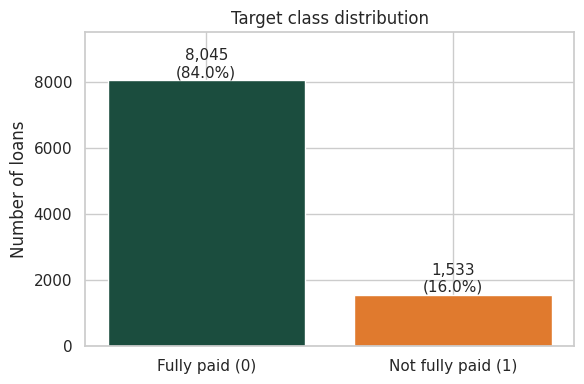

In [5]:
counts = df['not.fully.paid'].value_counts()
print(counts, '\n')
print((counts / len(df) * 100).round(2))

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(['Fully paid (0)', 'Not fully paid (1)'], counts.values, color=['#1B4D3E', '#E07A2E'])
for b, v in zip(bars, counts.values):
    ax.text(b.get_x() + b.get_width()/2, v + 100, f'{v:,}\n({v/len(df):.1%})', ha='center', fontsize=11)
ax.set_ylabel('Number of loans'); ax.set_title('Target class distribution')
ax.set_ylim(0, 9500)
plt.tight_layout(); plt.savefig('figs/class_balance.png', dpi=200); plt.show()

purpose
small_business        27.8
educational           20.1
home_improvement      17.0
all_other             16.6
debt_consolidation    15.2
credit_card           11.6
major_purchase        11.2
Name: not.fully.paid, dtype: float64


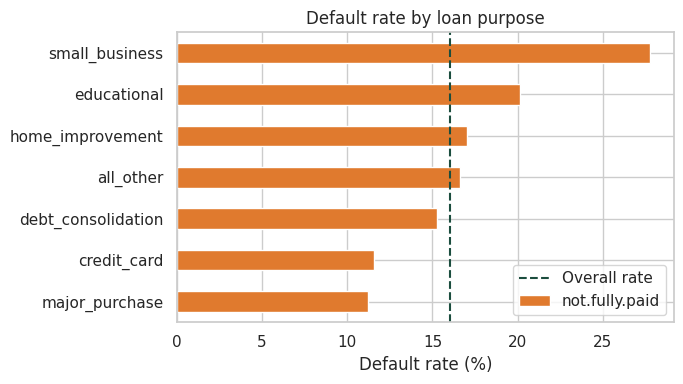

In [6]:
# Default rate by loan purpose
rate = df.groupby('purpose')['not.fully.paid'].mean().sort_values(ascending=False) * 100
print(rate.round(1))
fig, ax = plt.subplots(figsize=(7, 4))
rate.plot(kind='barh', color='#E07A2E', ax=ax)
ax.invert_yaxis(); ax.set_xlabel('Default rate (%)'); ax.set_ylabel('')
ax.set_title('Default rate by loan purpose')
ax.axvline(df['not.fully.paid'].mean()*100, color='#1B4D3E', ls='--', label='Overall rate')
ax.legend()
plt.tight_layout(); plt.savefig('figs/purpose_rate.png', dpi=200); plt.show()

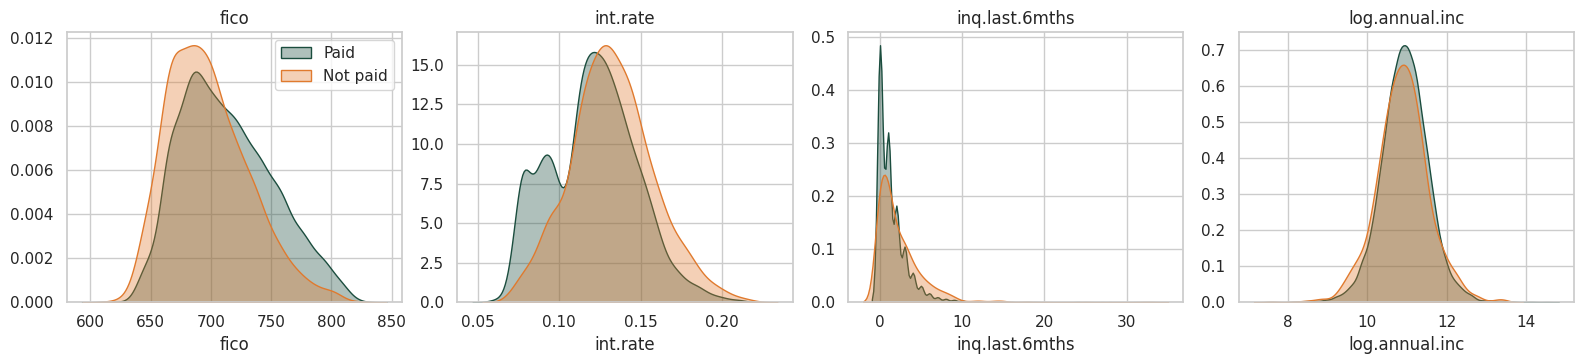

In [7]:
# Distributions of key numeric features by outcome
feats = ['fico', 'int.rate', 'inq.last.6mths', 'log.annual.inc']
fig, axes = plt.subplots(1, 4, figsize=(16, 3.8))
for ax, f in zip(axes, feats):
    for cls, col in [(0, '#1B4D3E'), (1, '#E07A2E')]:
        sns.kdeplot(df.loc[df['not.fully.paid'] == cls, f], ax=ax, fill=True, alpha=0.35,
                    color=col, label='Paid' if cls == 0 else 'Not paid', common_norm=False)
    ax.set_title(f); ax.set_ylabel('')
axes[0].legend()
plt.tight_layout(); plt.savefig('figs/feature_kde.png', dpi=200); plt.show()

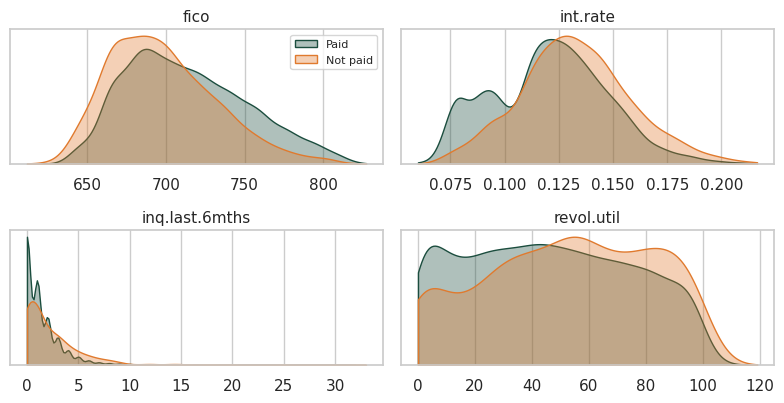

In [8]:
# Feature distributions used in the report and slides (fico, int.rate, inq.last.6mths, revol.util)
fig, axes = plt.subplots(2, 2, figsize=(8, 4.2))
for ax, f in zip(axes.ravel(), ['fico', 'int.rate', 'inq.last.6mths', 'revol.util']):
    for cls, col, lab in [(0, '#1B4D3E', 'Paid'), (1, '#E07A2E', 'Not paid')]:
        sns.kdeplot(df.loc[df['not.fully.paid'] == cls, f], ax=ax, fill=True, alpha=0.35, color=col, label=lab,
                    common_norm=False, clip=(df[f].min(), df[f].max()))
    ax.set_title(f, fontsize=11); ax.set_ylabel(''); ax.set_xlabel(''); ax.set_yticks([])
axes[0, 0].legend(fontsize=8)
plt.tight_layout(); plt.savefig('figs/kde_2x2.png', dpi=200); plt.show()

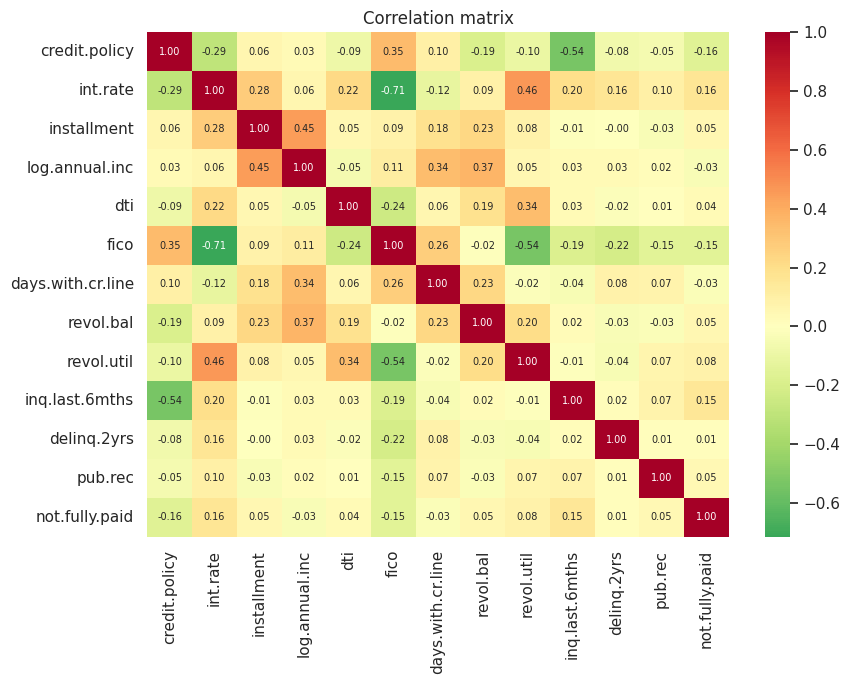

Correlation with target:
int.rate             0.160
credit.policy       -0.158
fico                -0.150
inq.last.6mths       0.149
revol.util           0.082
revol.bal            0.054
installment          0.050
pub.rec              0.049
dti                  0.037
log.annual.inc      -0.033
days.with.cr.line   -0.029
delinq.2yrs          0.009
Name: not.fully.paid, dtype: float64


In [9]:
# Correlation heatmap (numeric features)
num = df.drop(columns='purpose')
corr = num.corr()
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdYlGn_r', center=0, ax=ax, annot_kws={'size': 7})
ax.set_title('Correlation matrix')
plt.tight_layout(); plt.savefig('figs/corr.png', dpi=200); plt.show()
print('Correlation with target:')
print(corr['not.fully.paid'].drop('not.fully.paid').sort_values(key=abs, ascending=False).round(3))

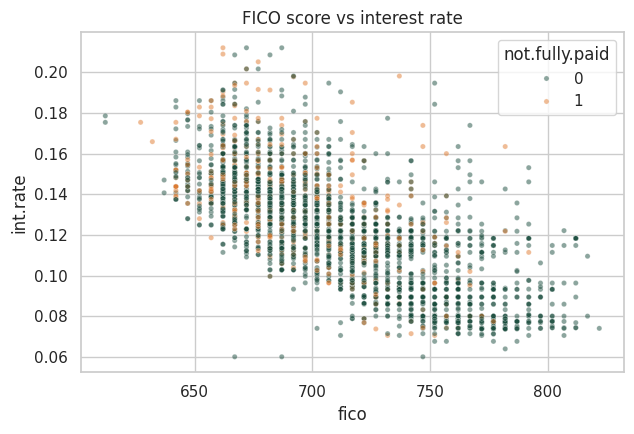

In [10]:
# FICO score vs interest rate: the interest rate already reflects credit risk
fig, ax = plt.subplots(figsize=(6.5, 4.5))
sns.scatterplot(data=df.sample(3000, random_state=SEED), x='fico', y='int.rate', hue='not.fully.paid',
                palette=['#1B4D3E', '#E07A2E'], alpha=0.5, s=14, ax=ax)
ax.set_title('FICO score vs interest rate')
plt.tight_layout(); plt.savefig('figs/fico_int.png', dpi=200); plt.show()

### EDA findings
- The data has no missing values or duplicate rows, so no imputation is needed.
- The classes are imbalanced: 84% of loans were repaid and 16% were not.
- Defaulters tend to have higher interest rates, lower FICO scores, and more recent credit inquiries (`inq.last.6mths`).
- Small business loans default at about twice the overall rate. Major purchase and credit card loans default least.
- `fico` and `int.rate` have a strong negative correlation of about −0.71, so the interest rate already reflects the lender's view of credit risk.

## 3. Preprocessing and feature engineering
The pipeline has five steps:
1. One-hot encode `purpose`. The 7 categories become 6 dummy columns, with the first dropped to avoid collinearity.
2. Add two engineered features: `installment_to_income` (yearly repayments as a share of income) and `credit_history_years`.
3. Split the data 80/20 with stratification, so both sets keep the 16% default rate.
4. Standardise the numeric features with `StandardScaler`. The scaler learns its parameters from the training set only, which prevents data leakage.
5. Apply SMOTE (Synthetic Minority Oversampling Technique) to the training set only. SMOTE creates synthetic defaulter records so the models train on balanced classes. The test set keeps its real 16% default rate.

In [11]:
data = df.copy()
data['annual_inc'] = np.exp(data['log.annual.inc'])
data['installment_to_income'] = data['installment'] * 12 / data['annual_inc']
data['credit_history_years'] = data['days.with.cr.line'] / 365.25
data = data.drop(columns=['annual_inc'])
data = pd.get_dummies(data, columns=['purpose'], drop_first=True, dtype=int)

X = data.drop(columns='not.fully.paid')
y = data['not.fully.paid']
print('Feature matrix:', X.shape)
print(list(X.columns))

Feature matrix: (9578, 20)
['credit.policy', 'int.rate', 'installment', 'log.annual.inc', 'dti', 'fico', 'days.with.cr.line', 'revol.bal', 'revol.util', 'inq.last.6mths', 'delinq.2yrs', 'pub.rec', 'installment_to_income', 'credit_history_years', 'purpose_credit_card', 'purpose_debt_consolidation', 'purpose_educational', 'purpose_home_improvement', 'purpose_major_purchase', 'purpose_small_business']


In [12]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
scaler = StandardScaler()
X_train_s = pd.DataFrame(scaler.fit_transform(X_train), columns=X.columns, index=X_train.index)
X_test_s = pd.DataFrame(scaler.transform(X_test), columns=X.columns, index=X_test.index)
print('Train:', X_train_s.shape, ' default rate', round(y_train.mean(), 4))
print('Test :', X_test_s.shape, ' default rate', round(y_test.mean(), 4))

smote = SMOTE(random_state=SEED)
X_train_bal, y_train_bal = smote.fit_resample(X_train_s, y_train)
print('\nAfter SMOTE (train only):', X_train_bal.shape)
print(y_train_bal.value_counts())

Train: (7662, 20)  default rate 0.16
Test : (1916, 20)  default rate 0.1602

After SMOTE (train only): (12872, 20)
not.fully.paid
0    6436
1    6436
Name: count, dtype: int64


## 4. Machine learning models
The notebook trains each model twice:
- Baseline: trained on the original, imbalanced training data.
- Balanced: trained on the SMOTE-balanced data, with hyperparameters tuned by 5-fold stratified cross-validation on F1-score.

The notebook then evaluates every model on the same untouched test set.

In [13]:
results = {}
preds, probas = {}, {}

def evaluate(name, y_true, y_pred, y_prob):
    m = {
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred, zero_division=0),
        'Recall': recall_score(y_true, y_pred),
        'F1': f1_score(y_true, y_pred),
        'ROC-AUC': roc_auc_score(y_true, y_prob),
    }
    results[name] = m
    preds[name], probas[name] = y_pred, y_prob
    print(f'{name}: ' + ', '.join(f'{k}={v:.3f}' for k, v in m.items()))
    return m

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

### 4.1 Baseline models (imbalanced training data)

In [14]:
baseline_models = {
    'Decision Tree': DecisionTreeClassifier(random_state=SEED),
    'Random Forest': RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1),
    'Naive Bayes': GaussianNB(),
    'Logistic Regression': LogisticRegression(max_iter=2000, random_state=SEED),
}
baseline_results = {}
for name, model in baseline_models.items():
    model.fit(X_train_s, y_train)
    yp = model.predict(X_test_s); pr = model.predict_proba(X_test_s)[:, 1]
    baseline_results[name] = evaluate(name + ' (baseline)', y_test, yp, pr)

Decision Tree (baseline): Accuracy=0.733, Precision=0.203, Recall=0.228, F1=0.215, ROC-AUC=0.529


Random Forest (baseline): Accuracy=0.837, Precision=0.250, Recall=0.010, F1=0.019, ROC-AUC=0.675
Naive Bayes (baseline): Accuracy=0.780, Precision=0.310, Recall=0.303, F1=0.306, ROC-AUC=0.661
Logistic Regression (baseline): Accuracy=0.839, Precision=0.483, Recall=0.046, F1=0.083, ROC-AUC=0.679


The baseline Random Forest and Logistic Regression reach about 84% accuracy but catch almost no defaulters, with recall close to zero. On this dataset, accuracy alone is misleading.

### 4.2 Decision Tree (tuned, SMOTE)

In [15]:
dt_grid = GridSearchCV(DecisionTreeClassifier(random_state=SEED),
                       {'max_depth': [4, 6, 8, 10], 'min_samples_leaf': [10, 30, 60], 'criterion': ['gini', 'entropy']},
                       scoring='f1', cv=cv, n_jobs=-1)
dt_grid.fit(X_train_bal, y_train_bal)
dt = dt_grid.best_estimator_
print('Best params:', dt_grid.best_params_)
evaluate('Decision Tree', y_test, dt.predict(X_test_s), dt.predict_proba(X_test_s)[:, 1]);

Best params: {'criterion': 'gini', 'max_depth': 10, 'min_samples_leaf': 30}
Decision Tree: Accuracy=0.780, Precision=0.266, Recall=0.212, F1=0.236, ROC-AUC=0.582


### 4.3 Random Forest (tuned, SMOTE)

In [16]:
rf_grid = GridSearchCV(RandomForestClassifier(random_state=SEED, n_jobs=-1),
                       {'n_estimators': [200], 'max_depth': [8, 12, 16], 'min_samples_leaf': [5, 15]},
                       scoring='f1', cv=cv, n_jobs=-1)
rf_grid.fit(X_train_bal, y_train_bal)
rf = rf_grid.best_estimator_
print('Best params:', rf_grid.best_params_)
evaluate('Random Forest', y_test, rf.predict(X_test_s), rf.predict_proba(X_test_s)[:, 1]);

Best params: {'max_depth': 16, 'min_samples_leaf': 5, 'n_estimators': 200}
Random Forest: Accuracy=0.773, Precision=0.287, Recall=0.280, F1=0.283, ROC-AUC=0.661


### 4.4 Gaussian Naïve Bayes (SMOTE)

In [17]:
nb_grid = GridSearchCV(GaussianNB(), {'var_smoothing': np.logspace(-11, -3, 9)}, scoring='f1', cv=cv)
nb_grid.fit(X_train_bal, y_train_bal)
nb = nb_grid.best_estimator_
print('Best params:', nb_grid.best_params_)
evaluate('Naive Bayes', y_test, nb.predict(X_test_s), nb.predict_proba(X_test_s)[:, 1]);

Best params: {'var_smoothing': np.float64(1e-11)}
Naive Bayes: Accuracy=0.654, Precision=0.244, Recall=0.550, F1=0.338, ROC-AUC=0.663


### 4.5 Logistic Regression (additional linear baseline, SMOTE)

In [18]:
lr_grid = GridSearchCV(LogisticRegression(max_iter=3000, random_state=SEED),
                       {'C': [0.01, 0.1, 1, 10]}, scoring='f1', cv=cv)
lr_grid.fit(X_train_bal, y_train_bal)
lr = lr_grid.best_estimator_
print('Best params:', lr_grid.best_params_)
evaluate('Logistic Regression', y_test, lr.predict(X_test_s), lr.predict_proba(X_test_s)[:, 1]);

Best params: {'C': 0.1}
Logistic Regression: Accuracy=0.635, Precision=0.239, Recall=0.586, F1=0.340, ROC-AUC=0.681


## 5. Deep learning model: multilayer ANN
The network has an input layer of 25 features, three hidden layers (Dense 64, Dense 32, and Dense 16, all with ReLU activation), and a single sigmoid output. Dropout of 0.3 follows each of the first two hidden layers.
- Loss is binary cross-entropy, and the optimiser is Adam with a learning rate of 0.001.
- The training data is the SMOTE-balanced set, with 20% held out for validation.
- Early stopping monitors validation loss (patience 10) and restores the best weights to limit overfitting.

In [19]:
tf.keras.utils.set_random_seed(SEED)
ann = keras.Sequential([
    keras.layers.Input(shape=(X_train_bal.shape[1],)),
    keras.layers.Dense(64, activation='relu'),
    keras.layers.Dropout(0.3),
    keras.layers.Dense(32, activation='relu'),
    keras.layers.Dropout(0.3),
    keras.layers.Dense(16, activation='relu'),
    keras.layers.Dense(1, activation='sigmoid'),
])
ann.compile(optimizer=keras.optimizers.Adam(1e-3), loss='binary_crossentropy',
            metrics=['accuracy', keras.metrics.AUC(name='auc')])
ann.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         1,344 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,969 (15.50 KB)

 Trainable params: 3,969 (15.50 KB)

 Non-trainable params: 0 (0.00 B)

Epochs trained: 138


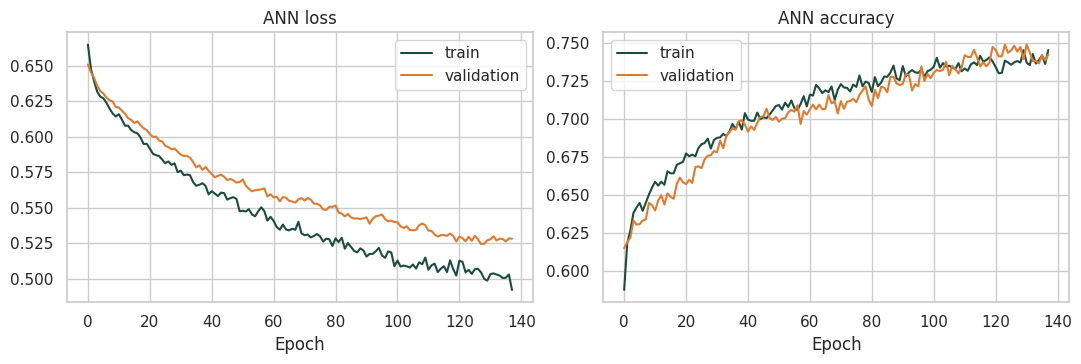

In [20]:
es = keras.callbacks.EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)
Xb = X_train_bal.values.astype('float32'); yb = y_train_bal.values.astype('float32')
perm = np.random.RandomState(SEED).permutation(len(Xb))
history = ann.fit(Xb[perm], yb[perm], validation_split=0.2, epochs=150, batch_size=64,
                  callbacks=[es], verbose=0)
print('Epochs trained:', len(history.history['loss']))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].plot(history.history['loss'], label='train', color='#1B4D3E')
axes[0].plot(history.history['val_loss'], label='validation', color='#E07A2E')
axes[0].set_title('ANN loss'); axes[0].set_xlabel('Epoch'); axes[0].legend()
axes[1].plot(history.history['accuracy'], label='train', color='#1B4D3E')
axes[1].plot(history.history['val_accuracy'], label='validation', color='#E07A2E')
axes[1].set_title('ANN accuracy'); axes[1].set_xlabel('Epoch'); axes[1].legend()
plt.tight_layout(); plt.savefig('figs/ann_history.png', dpi=200); plt.show()

In [21]:
ann_prob = ann.predict(X_test_s.values.astype('float32'), verbose=0).ravel()
evaluate('ANN (MLP)', y_test, (ann_prob >= 0.5).astype(int), ann_prob);

ANN (MLP): Accuracy=0.637, Precision=0.216, Recall=0.479, F1=0.297, ROC-AUC=0.631


## 6. Model comparison and evaluation

In [22]:
main = ['Decision Tree', 'Random Forest', 'Naive Bayes', 'Logistic Regression', 'ANN (MLP)']
comp = pd.DataFrame({k: results[k] for k in main}).T.round(3)
print('Balanced models (SMOTE) on the untouched test set:')
comp.sort_values('F1', ascending=False)

Balanced models (SMOTE) on the untouched test set:


,Accuracy,Precision,Recall,F1,ROC-AUC
Logistic Regression,0.635,0.239,0.586,0.340,0.681
Naive Bayes,0.654,0.244,0.550,0.338,0.663
ANN (MLP),0.637,0.216,0.479,0.297,0.631
Random Forest,0.773,0.287,0.280,0.283,0.661
Decision Tree,0.780,0.266,0.212,0.236,0.582


Logistic Regression has the best F1 score and recall and ROC AUC. Naïve Bayes is a close second. The tree models keep the highest accuracy but catch only about one defaulter in four. The neural network sits between the two groups.

In [23]:
base = pd.DataFrame({k: results[k + ' (baseline)'] for k in baseline_models}).T.round(3)
print('Baseline models (no rebalancing):')
base

Baseline models (no rebalancing):


,Accuracy,Precision,Recall,F1,ROC-AUC
Decision Tree,0.733,0.203,0.228,0.215,0.529
Random Forest,0.837,0.250,0.010,0.019,0.675
Naive Bayes,0.780,0.310,0.303,0.306,0.661
Logistic Regression,0.839,0.483,0.046,0.083,0.679


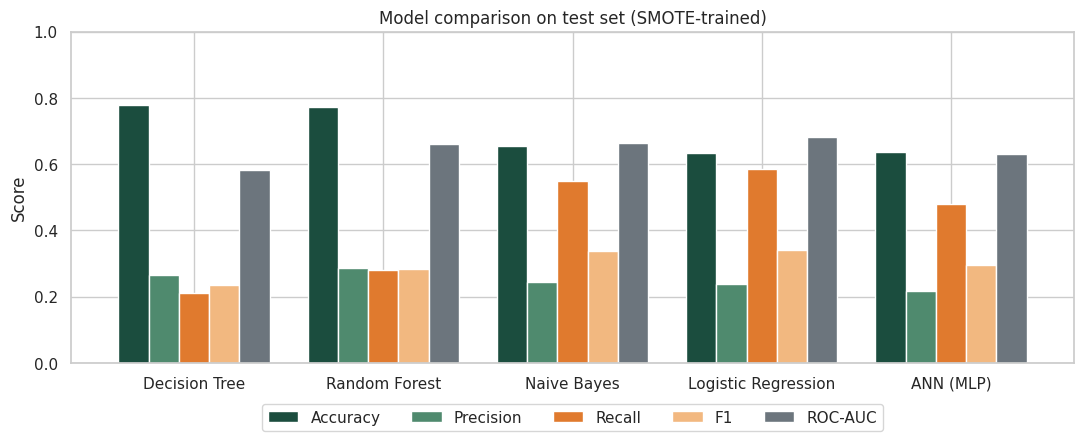

In [24]:
# Grouped bar chart of metrics
plot_df = comp[['Accuracy', 'Precision', 'Recall', 'F1', 'ROC-AUC']]
colors = ['#1B4D3E', '#4F8A6E', '#E07A2E', '#F2B880', '#6C757D']
ax = plot_df.plot(kind='bar', figsize=(11, 4.6), color=colors, width=0.8)
ax.set_ylim(0, 1); ax.set_ylabel('Score'); ax.set_title('Model comparison on test set (SMOTE-trained)')
ax.set_xticklabels(plot_df.index, rotation=0)
ax.legend(ncol=5, loc='upper center', bbox_to_anchor=(0.5, -0.1))
plt.tight_layout(); plt.savefig('figs/metrics_bar.png', dpi=200); plt.show()

                     Baseline accuracy  Balanced accuracy  Baseline recall  \
Decision Tree                    0.733              0.780            0.228   
Random Forest                    0.837              0.773            0.010   
Naive Bayes                      0.780              0.654            0.303   
Logistic Regression              0.839              0.635            0.046   

                     Balanced recall  
Decision Tree                  0.212  
Random Forest                  0.280  
Naive Bayes                    0.550  
Logistic Regression            0.586  


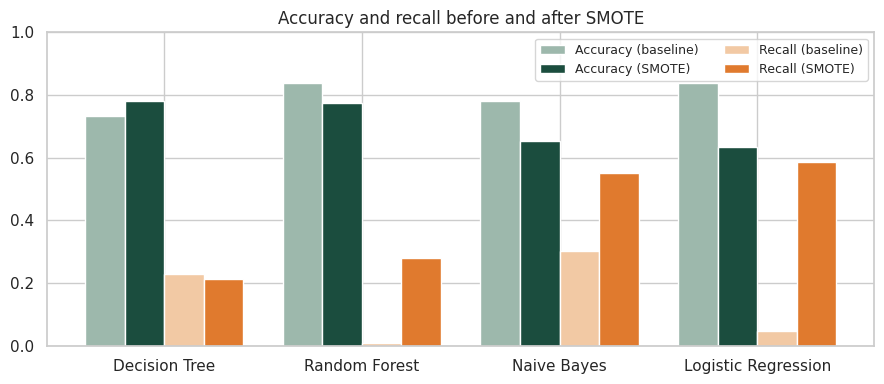

In [25]:
# Accuracy vs recall trade-off: baseline vs balanced
tr = pd.DataFrame({
    'Baseline accuracy': base['Accuracy'].values, 'Balanced accuracy': comp.loc[list(baseline_models), 'Accuracy'].values,
    'Baseline recall': base['Recall'].values, 'Balanced recall': comp.loc[list(baseline_models), 'Recall'].values,
}, index=list(baseline_models))
print(tr.round(3))
fig, ax = plt.subplots(figsize=(9, 4))
x = np.arange(len(tr)); w = 0.2
ax.bar(x - 1.5*w, tr['Baseline accuracy'], w, color='#9DB8AC', label='Accuracy (baseline)')
ax.bar(x - 0.5*w, tr['Balanced accuracy'], w, color='#1B4D3E', label='Accuracy (SMOTE)')
ax.bar(x + 0.5*w, tr['Baseline recall'], w, color='#F2C9A4', label='Recall (baseline)')
ax.bar(x + 1.5*w, tr['Balanced recall'], w, color='#E07A2E', label='Recall (SMOTE)')
ax.set_xticks(x); ax.set_xticklabels(tr.index); ax.set_ylim(0, 1)
ax.set_title('Accuracy and recall before and after SMOTE')
ax.legend(ncol=2, fontsize=9)
plt.tight_layout(); plt.savefig('figs/tradeoff.png', dpi=200); plt.show()

Recall rose for three of the four models after SMOTE and tuning. Logistic Regression went from 4.6% to 58.6% and Random Forest from 1.0% to 28.0%. The tuned Decision Tree stayed about the same. Accuracy fell by 6 to 20 points for the three models that improved.

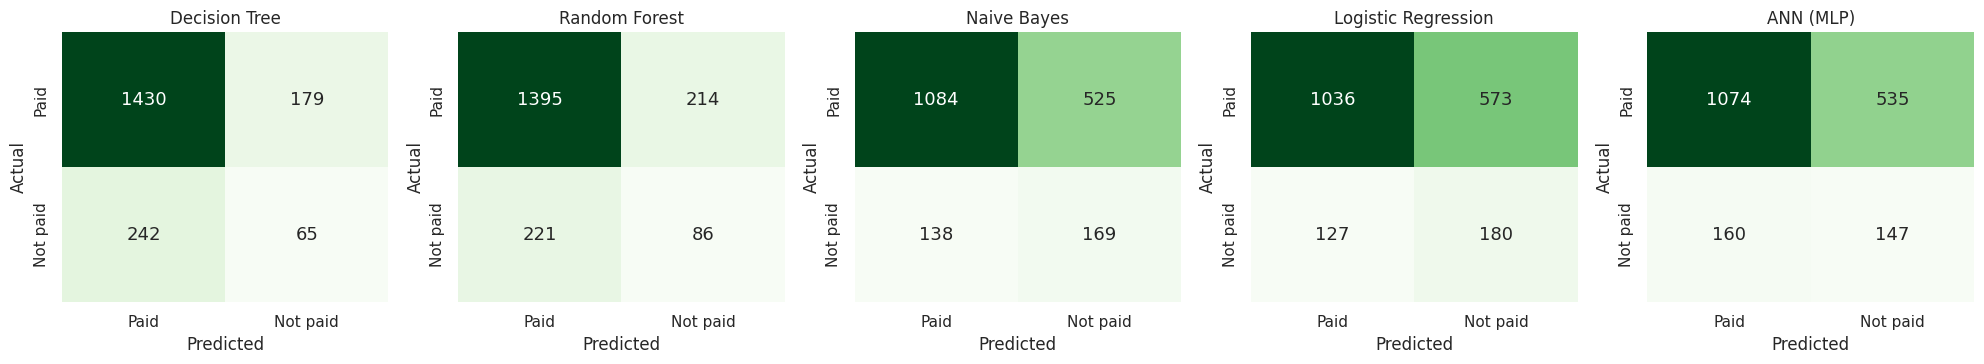

In [26]:
# Confusion matrices
fig, axes = plt.subplots(1, 5, figsize=(20, 3.8))
for ax, k in zip(axes, main):
    cm = confusion_matrix(y_test, preds[k])
    sns.heatmap(cm, annot=True, fmt='d', cmap='Greens', cbar=False, ax=ax,
                xticklabels=['Paid', 'Not paid'], yticklabels=['Paid', 'Not paid'], annot_kws={'size': 13})
    ax.set_title(k); ax.set_xlabel('Predicted'); ax.set_ylabel('Actual')
plt.tight_layout(); plt.savefig('figs/confusion.png', dpi=200); plt.show()

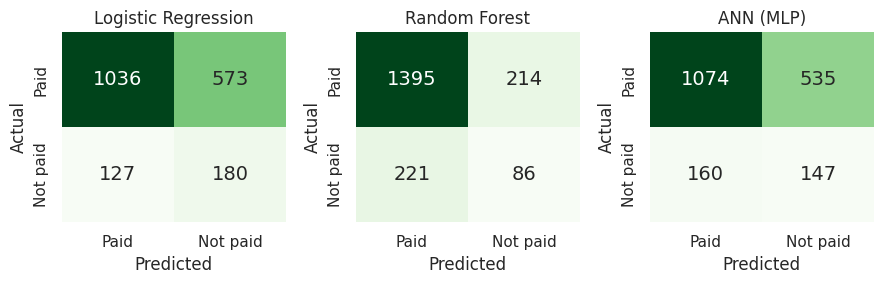

In [27]:
# Three-model version used in the report and slides
fig, axes = plt.subplots(1, 3, figsize=(9, 3))
for ax, k in zip(axes, ['Logistic Regression', 'Random Forest', 'ANN (MLP)']):
    sns.heatmap(confusion_matrix(y_test, preds[k]), annot=True, fmt='d', cmap='Greens', cbar=False, ax=ax,
                xticklabels=['Paid', 'Not paid'], yticklabels=['Paid', 'Not paid'], annot_kws={'size': 14})
    ax.set_title(k, fontsize=12); ax.set_xlabel('Predicted'); ax.set_ylabel('Actual')
plt.tight_layout(); plt.savefig('figs/cm3.png', dpi=200); plt.show()

Logistic Regression catches 180 of the 307 defaulters but flags 573 good loans. Random Forest flags only 214 good loans but misses 221 defaulters. The better choice depends on what a missed default costs compared with a manual review.

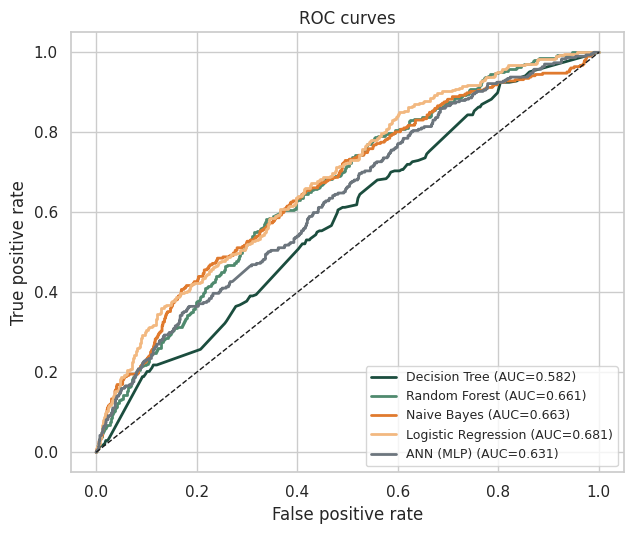

In [28]:
# ROC curves
fig, ax = plt.subplots(figsize=(6.5, 5.5))
for k, c in zip(main, colors):
    fpr, tpr, _ = roc_curve(y_test, probas[k])
    ax.plot(fpr, tpr, color=c, lw=2, label=f"{k} (AUC={results[k]['ROC-AUC']:.3f})")
ax.plot([0, 1], [0, 1], 'k--', lw=1)
ax.set_xlabel('False positive rate'); ax.set_ylabel('True positive rate'); ax.set_title('ROC curves')
ax.legend(fontsize=9, loc='lower right')
plt.tight_layout(); plt.savefig('figs/roc.png', dpi=200); plt.show()

Every model ranks defaulters better than chance. The AUC values range from 0.58 to 0.68 so the features carry only moderate signal.

inq.last.6mths           0.2369
fico                     0.1064
int.rate                 0.1008
installment_to_income    0.0635
revol.util               0.0595
log.annual.inc           0.0579
dti                      0.0570
installment              0.0566
revol.bal                0.0545
credit_history_years     0.0525
dtype: float64


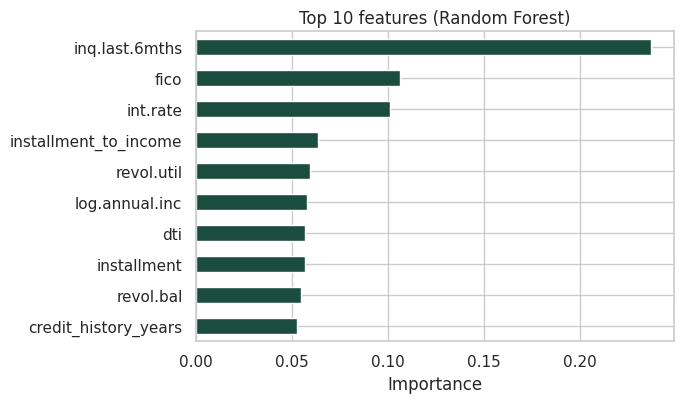

In [29]:
# Random Forest feature importance
imp = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False).head(10)
print(imp.round(4))
fig, ax = plt.subplots(figsize=(7, 4.2))
imp.sort_values().plot(kind='barh', color='#1B4D3E', ax=ax)
ax.set_title('Top 10 features (Random Forest)'); ax.set_xlabel('Importance')
plt.tight_layout(); plt.savefig('figs/importance.png', dpi=200); plt.show()

Recent credit inquiries lead by a wide margin. FICO score and interest rate follow. The engineered feature installment_to_income ranks fourth.

In [30]:
# 5-fold cross-validated F1 on the training data (SMOTE inside each fold via pipeline) for robustness
from imblearn.pipeline import Pipeline as ImbPipeline
cv_scores = {}
for name, est in [('Decision Tree', dt), ('Random Forest', rf), ('Naive Bayes', nb), ('Logistic Regression', lr)]:
    pipe = ImbPipeline([('smote', SMOTE(random_state=SEED)), ('clf', est)])
    s = cross_val_score(pipe, X_train_s, y_train, cv=cv, scoring='f1', n_jobs=-1)
    cv_scores[name] = (s.mean(), s.std())
    print(f'{name}: CV F1 = {s.mean():.3f} ± {s.std():.3f}')

Decision Tree: CV F1 = 0.269 ± 0.009


Random Forest: CV F1 = 0.283 ± 0.020
Naive Bayes: CV F1 = 0.338 ± 0.013


Logistic Regression: CV F1 = 0.344 ± 0.012


In [31]:
print(classification_report(y_test, preds['ANN (MLP)'], target_names=['Paid', 'Not paid']))

              precision    recall  f1-score   support

        Paid       0.87      0.67      0.76      1609
    Not paid       0.22      0.48      0.30       307

    accuracy                           0.64      1916
   macro avg       0.54      0.57      0.53      1916
weighted avg       0.77      0.64      0.68      1916



In [32]:
out = {'balanced': comp.to_dict(orient='index'), 'baseline': base.to_dict(orient='index'),
       'cv_f1': {k: list(v) for k, v in cv_scores.items()},
       'best_params': {'Decision Tree': dt_grid.best_params_, 'Random Forest': rf_grid.best_params_,
                       'Naive Bayes': {k: float(v) for k, v in nb_grid.best_params_.items()}, 'Logistic Regression': lr_grid.best_params_},
       'ann_epochs': len(history.history['loss']),
       'confusion': {k: confusion_matrix(y_test, preds[k]).tolist() for k in main},
       'importance': imp.round(4).to_dict()}
with open('results.json', 'w') as f: json.dump(out, f, indent=2, default=str)
print('Saved results.json')

Saved results.json


## 7. Conclusion
- Class imbalance dominates this problem. The baseline Random Forest scored 83.7% accuracy but caught only 3 of the 307 defaulters (recall 1.0%). Choosing by accuracy would have picked the worst model.
- SMOTE raised recall for three of the four models. Random Forest recall rose from 1.0% to 28.0%, Naïve Bayes from 30.3% to 55.0%, and Logistic Regression from 4.6% to 58.6%. The tuned Decision Tree's recall stayed about the same (22.8% baseline, 21.2% balanced).
- Logistic Regression (F1 0.340, ROC-AUC 0.681) and Naïve Bayes (F1 0.338, ROC-AUC 0.663) give the best balance of precision and recall. Five-fold cross-validation gives the same ranking, with a CV F1 of about 0.34 for both.
- Among the balanced models, the Decision Tree (78.0%) and Random Forest (77.3%) have the highest accuracy, but they miss about three in four defaulters.
- The ANN (F1 0.297, recall 47.9%) did not beat the simpler models. With about 9,600 rows and 25 tabular features, a deep network has little extra structure to learn. Because it trained on SMOTE data, it kept improving on synthetic records for 138 epochs without matching gains on the real test data.
- The signal is moderate. ROC-AUC ranges from 0.58 to 0.68, so the available features explain only part of the repayment outcome. Recent credit inquiries, FICO score, and interest rate are the strongest predictors.

Future work: tune the decision threshold to a business cost ratio, because a missed default costs far more than a rejected good loan. Gradient boosting (XGBoost or LightGBM) and extra borrower features, such as employment length and loan term, are also worth testing.

The report lists the references in APA 7th edition format.